D:\work\sqlite\anaconda\lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
C:\Users\gaobin\AppData\Local\Temp\ipykernel_11292\2769527146.py:118: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  for province_name in pd.unique([r[0] for r in repaired_records]):


Province distance threshold: 10 km
Province adjacency edges (distance <= threshold): 68
Guangdong-Hainan distance (km): 15.710
Building the three flow-level distance-threshold fusion edge sets...
Province distance-threshold edges: 68
E1 (same origin, adjacent destinations): 1972
E2 (same destination, adjacent origins): 1972
E3 (adjacent origins AND adjacent destinations): 8610
Note: E3 can naturally exceed E1/E2 because both endpoints may vary; each class is separately normalized to total base weight n_obs.
E1 independent validation: actual=1972, expected=1972, missing=0, extra=0
E2 independent validation: actual=1972, expected=1972, missing=0, extra=0
E3 independent validation: actual=8610, expected=8610, missing=0, extra=0
All three flow-level distance-threshold edge sets passed independent validation.
OD graph components: 3; sizes: [870, 30, 30]
Base penalty weight totals (E1, E2, E3): (930.000, 930.000, 930.000)
rho_b=500.0; OLS-fixed intercept=-33756
Response scale: sd=126309; raw

C:\Users\gaobin\AppData\Local\Temp\ipykernel_11292\2769527146.py:384: UserWarning: OD fusion graph is disconnected. Check island provinces and interpret these as structural components, not learned economic groups.
  warnings.warn('OD fusion graph is disconnected. Check island provinces and '


  start diagnostics: eligible=True, outer=True, outer_change=0.00192, ADMM failures(total/last sweep)=0/0, residual ratios=(0.159,0.997), CG failures=0

Coordinate sweep 1/4
  Optimizing lambda_1...
    lambda_1=1e-05 | BIC=41200.59 | df=3957 | RSS=3.7849e+09 | time=14.5s
    lambda_1=5e-05 | BIC=41112.46 | df=3944 | RSS=3.7879e+09 | time=14.6s
    lambda_1=0.0001 | BIC=40997.20 | df=3927 | RSS=3.7917e+09 | time=14.5s
    lambda_1=0.0005 | BIC=40191.51 | df=3808 | RSS=3.8232e+09 | time=14.4s
    lambda_1=0.001 | BIC=39374.76 | df=3687 | RSS=3.8658e+09 | time=14.5s
    lambda_1=0.002 | BIC=38112.43 | df=3499 | RSS=3.9613e+09 | time=14.4s
    lambda_1=0.005 | BIC=36082.45 | df=3190 | RSS=4.3268e+09 | time=14.5s
    lambda_1=0.01 | BIC=34586.27 | df=2947 | RSS=5.1655e+09 | time=14.6s
    lambda_1=0.03 | BIC=31551.52 | df=2406 | RSS=1.0538e+10 | time=14.6s
    lambda_1=0.05 | BIC=27659.22 | df=1769 | RSS=1.7313e+10 | time=25.9s
    lambda_1=0.1 | BIC=24550.85 | df=1200 | RSS=4.0089e+10 | t

    lambda_3=0.1 | BIC=20882.35 | df=425 | RSS=2.3101e+11 | time=13.3s
  Selected lambda_3=0.1; current BIC=20866.38
End of sweep 3: lambdas=(0.1, 0.1, 0.1), BIC=20866.38, selection_score=20866.38, improvement=0, relative improvement=0
Coordinate search stopped: relative BIC improvement is below tolerance.

Lowest raw-BIC candidate among evaluated models:
                  stage  lambda1  lambda2  lambda3          bic  selection_score          rss  df  min_groups  groups_Outgeo_GDP  groups_Outgeo_POP  groups_Outgeo_INV  groups_Ingeo_GDP  groups_Ingeo_INV  groups_Ingeo_POP  groups_distance
ordinary_sweep2_lambda1      0.1      0.1      0.1 20866.379894     20866.379894 2.321374e+11 422          32                 34                130                 32                87                40                61               38

Lowest constrained selection-score candidate among evaluated models:
                  stage  lambda1  lambda2  lambda3          bic  selection_score          rss  d

C:\Users\gaobin\AppData\Local\Temp\ipykernel_11292\2769527146.py:1110: UserWarning: Selected lambda_1=0.1 is on its search-grid boundary; consider extending that coordinate's grid and rerunning the search.
  warnings.warn(
C:\Users\gaobin\AppData\Local\Temp\ipykernel_11292\2769527146.py:1110: UserWarning: Selected lambda_2=0.1 is on its search-grid boundary; consider extending that coordinate's grid and rerunning the search.
  warnings.warn(
C:\Users\gaobin\AppData\Local\Temp\ipykernel_11292\2769527146.py:1110: UserWarning: Selected lambda_3=0.1 is on its search-grid boundary; consider extending that coordinate's grid and rerunning the search.
  warnings.warn(


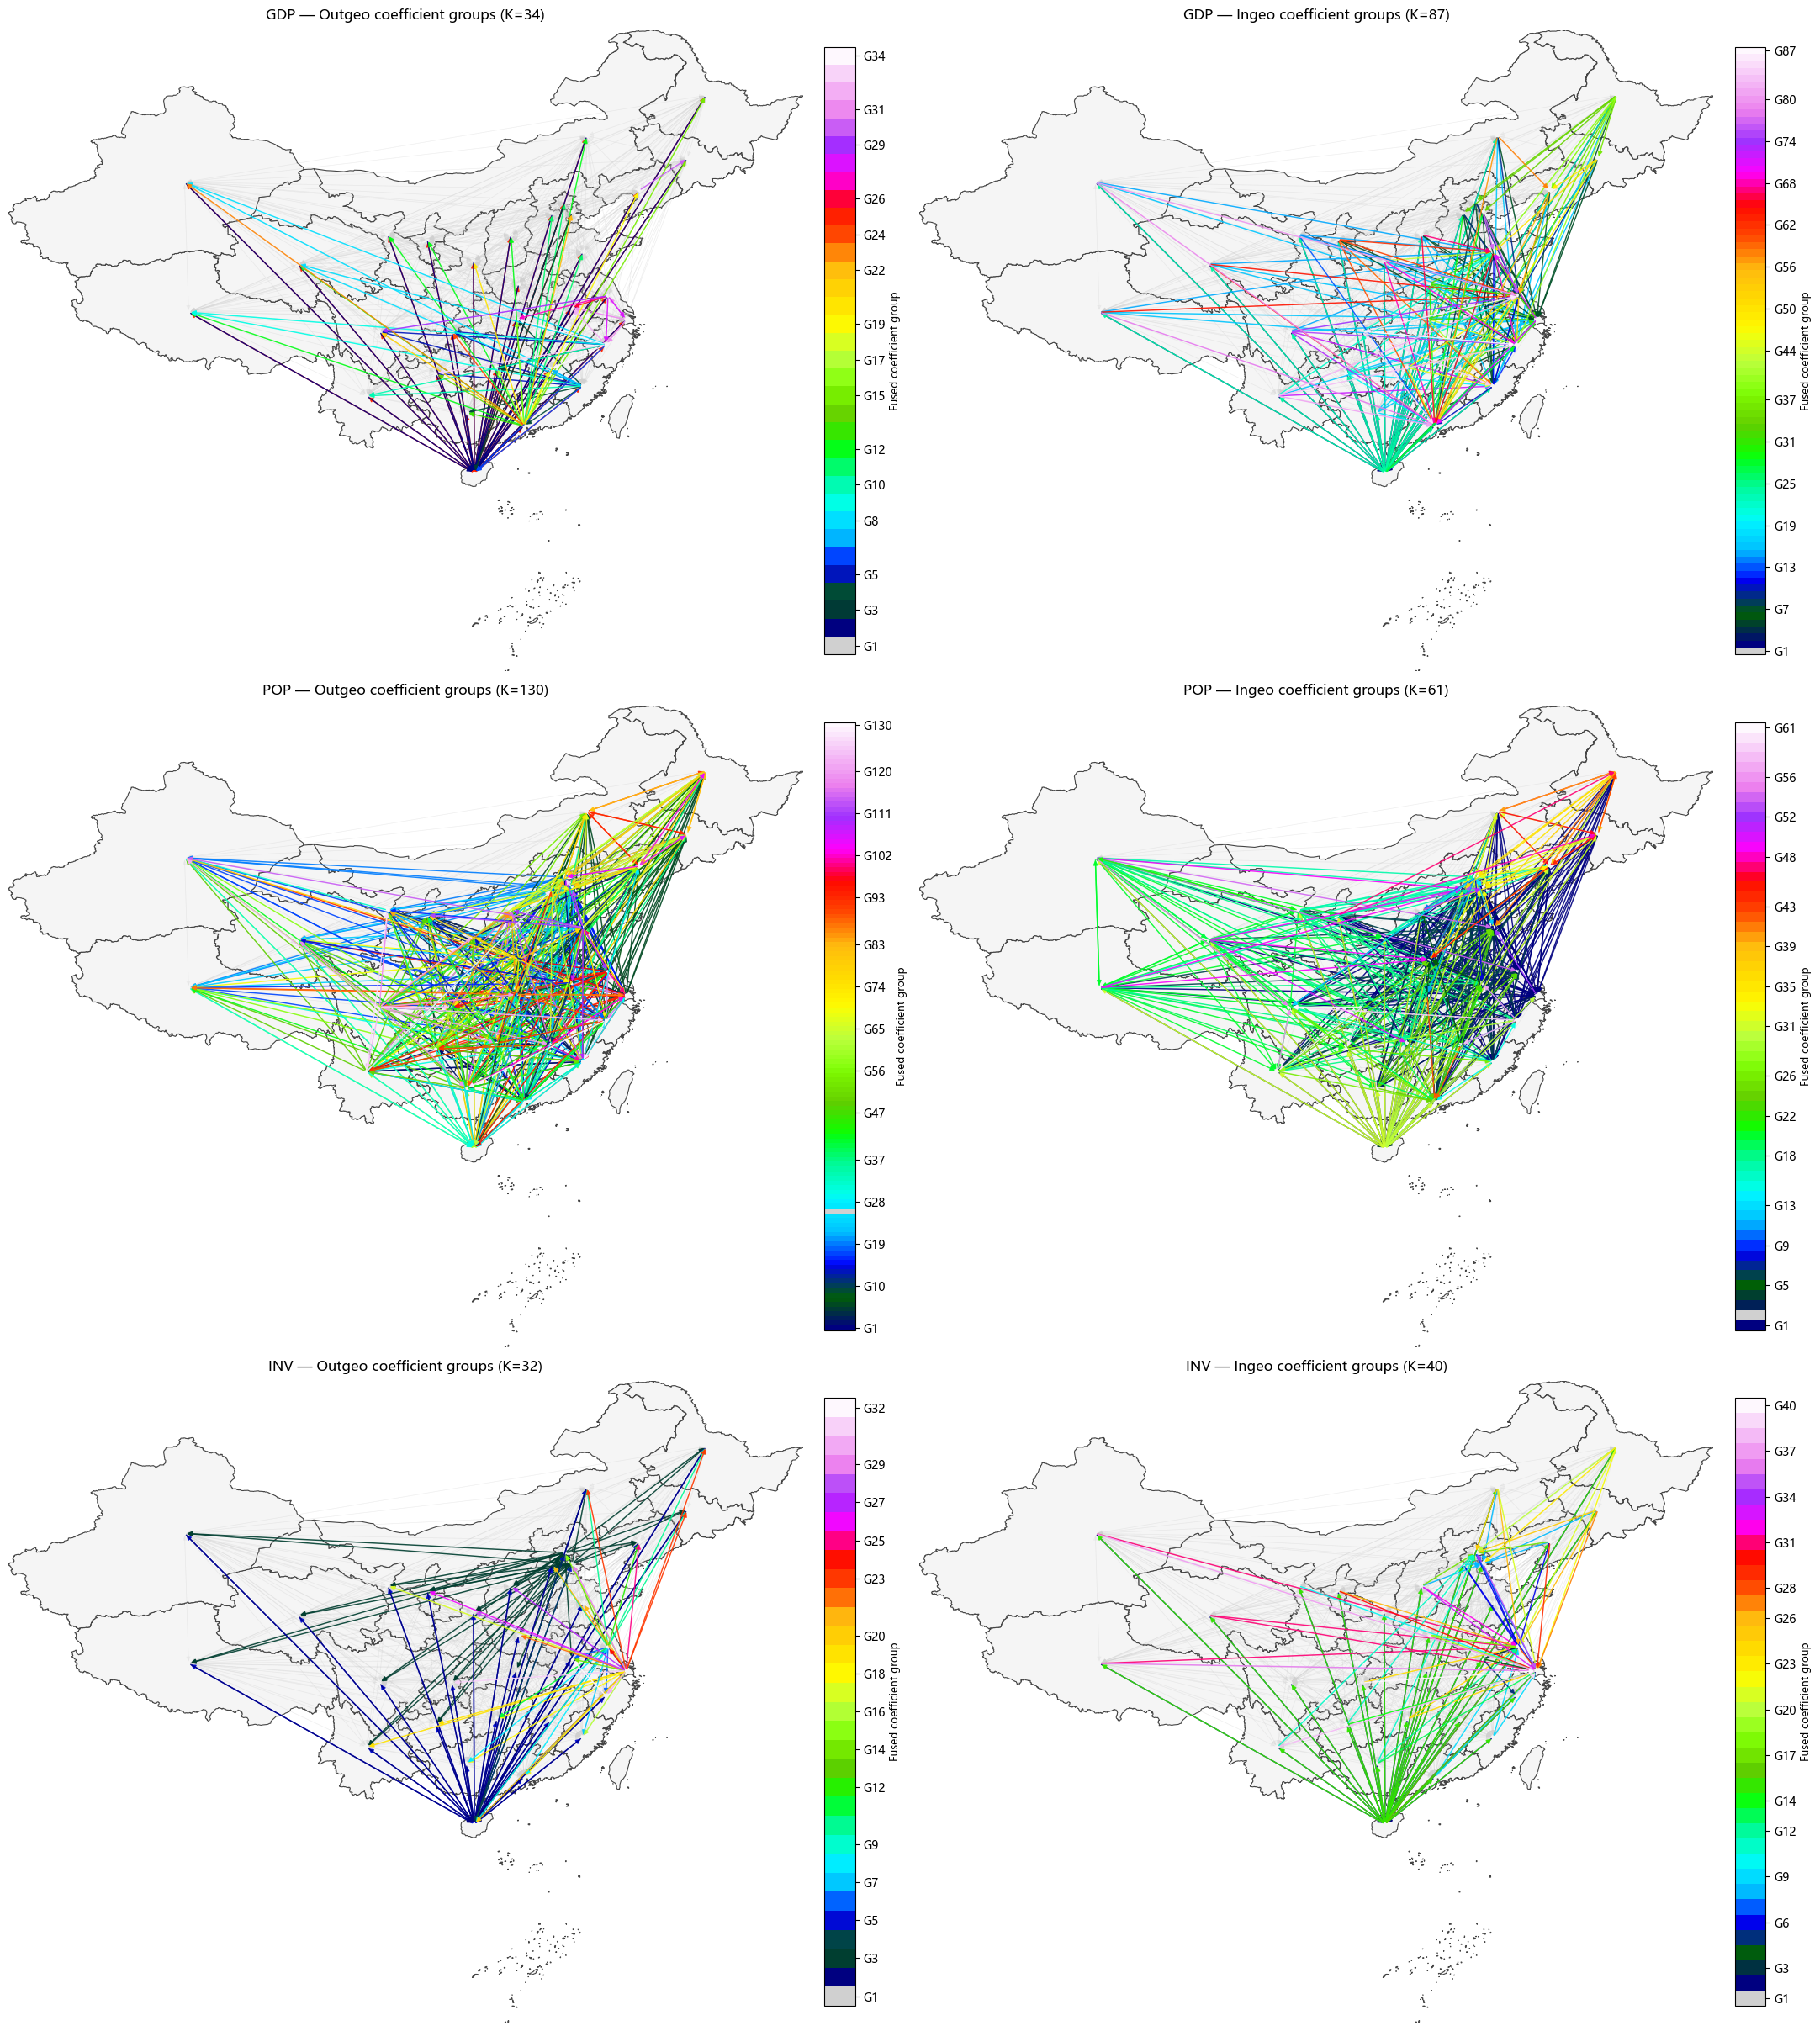

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib import colors
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import time
import warnings
from shapely import make_valid
from shapely.geometry import Polygon, MultiPolygon, GeometryCollection
from shapely.ops import unary_union

plt.rcParams["font.sans-serif"] = [
    "Microsoft YaHei", "SimHei", "SimSun",
    "Noto Sans CJK SC", "Arial Unicode MS",
]
plt.rcParams["axes.unicode_minus"] = False

# ---------- 1. 读取数据 ----------
df = pd.read_csv("sevenpopulation.csv")
base_map = gpd.read_file(
    r"D:\work\ARCGIS\省份划分地图\省份划分地图.shp",
    encoding='utf-8'
)

y_col = "迁出量"
feature_cols = ['Outgeo_GDP','Outgeo_POP','Outgeo_INV','Ingeo_GDP','Ingeo_INV','Ingeo_POP',"distance"]

y = df[y_col].to_numpy(dtype=float)
x_df = df[feature_cols].astype(float)
x = x_df.to_numpy(dtype=float)

# 标准化特征
x_mean = x.mean(axis=0)
x_std = x.std(axis=0)
x_std[x_std < 1e-12] = 1.0
x_std_scaled = (x - x_mean) / x_std

y_mean = float(np.mean(y))
y_scale = float(np.std(y))
if not np.isfinite(y_scale) or y_scale < 1e-12:
    raise ValueError("Response variable has zero or invalid standard deviation.")
# Optimize on a standardized response scale; convert all reported coefficients
# and RSS back to the original units after fitting.
y_centered = (y - y_mean) / y_scale

# 省份名称标准化映射
name_map = {
    "北京市": "北京", "天津市": "天津", "上海市": "上海", "重庆市": "重庆",
    "内蒙古自治区": "内蒙古", "广西壮族自治区": "广西", "宁夏回族自治区": "宁夏",
    "新疆维吾尔自治区": "新疆", "西藏自治区": "西藏",
    "香港特别行政区": "香港", "澳门特别行政区": "澳门", "台湾省": "台湾",
}

def normalize_name(name: str) -> str:
    if name in name_map:
        return name_map[name]
    for suffix in ["省", "市", "自治区", "特别行政区"]:
        if name.endswith(suffix):
            return name[:-len(suffix)]
    return name

# 统一 CSV 与地图中的省份名称，避免“北京市”和“北京”无法匹配
origin_std = df["Outgeo"].astype(str).apply(normalize_name)
dest_std = df["Ingeo"].astype(str).apply(normalize_name)
provinces = pd.unique(pd.concat([origin_std, dest_std], ignore_index=True)).tolist()

# 统一地图名称，并先修复无效几何，再按省份合并。
# 直接 dissolve 会对原始几何执行 union；若 Shapefile 含自相交/重叠等无效面，
# GEOS 可能抛出 TopologyException。下面先 make_valid，再只保留面要素。
base_map["name_std"] = base_map["name"].astype(str).apply(normalize_name)
base_map = base_map[
    base_map["name_std"].notna() &
    (base_map["name_std"] != "None") &
    base_map.geometry.notna()
].copy()

if base_map.crs is None:
    base_map = base_map.set_crs("EPSG:4326")

def _polygon_parts(geom):
    """Repair one geometry and return only polygonal parts."""
    if geom is None or geom.is_empty:
        return []
    try:
        fixed = make_valid(geom)
    except Exception:
        # Fallback for difficult legacy geometries.
        fixed = geom.buffer(0)
    if fixed is None or fixed.is_empty:
        return []
    if isinstance(fixed, Polygon):
        return [fixed] if fixed.area > 0 else []
    if isinstance(fixed, MultiPolygon):
        return [g for g in fixed.geoms if not g.is_empty and g.area > 0]
    if isinstance(fixed, GeometryCollection):
        parts = []
        for subgeom in fixed.geoms:
            parts.extend(_polygon_parts(subgeom))
        return parts
    return []

# 先逐要素修复。若原始要素被修复成 GeometryCollection，只保留其中的面部分。
repaired_records = []
for province_name, geom in zip(base_map["name_std"], base_map.geometry):
    parts = _polygon_parts(geom)
    if not parts:
        warnings.warn(f"地图要素 {province_name} 修复后没有有效面，已跳过。")
        continue
    repaired_records.append((province_name, unary_union(parts)))

if not repaired_records:
    raise RuntimeError("Shapefile 中没有可用的省级面几何。")

# 按标准化省名合并同一省份的多个面（例如岛屿或分幅记录）。
merged_records = []
for province_name in pd.unique([r[0] for r in repaired_records]):
    parts = []
    for name, geom in repaired_records:
        if name == province_name:
            parts.extend(_polygon_parts(geom))
    if not parts:
        continue
    merged = unary_union(parts)
    if not merged.is_valid:
        merged = make_valid(merged)
        fixed_parts = _polygon_parts(merged)
        if not fixed_parts:
            warnings.warn(f"省份 {province_name} 合并后仍无有效面，已跳过。")
            continue
        merged = unary_union(fixed_parts)
    merged_records.append({"name_std": province_name, "geometry": merged})

base_map = gpd.GeoDataFrame(
    merged_records,
    geometry="geometry",
    crs=base_map.crs
)

# 最后再检查一次几何有效性，避免无效面进入后续 boundary.intersection。
invalid_names = base_map.loc[~base_map.geometry.is_valid, "name_std"].tolist()
if invalid_names:
    raise RuntimeError(
        "以下省份几何修复后仍无效：" + ", ".join(invalid_names)
    )

centroids = base_map.set_index("name_std")["geometry"].representative_point()

# ---------- 2. Province adjacency: minimum polygon distance <= 10 km ----------
# Use minimum distance between complete province polygons, NOT centroid distance.
# Each pair is projected into its own local azimuthal-equidistant CRS to avoid
# the latitude-dependent distortion of EPSG:3857 over China.
from pyproj import CRS, Transformer
from shapely.ops import transform as shapely_transform

DISTANCE_THRESHOLD_KM = 10.0
idx = {name: i for i, name in enumerate(provinces)}
n_prov = len(provinces)
geom_ll = base_map.to_crs("EPSG:4326").set_index("name_std")["geometry"]
missing_map_names = sorted(set(provinces) - set(geom_ll.index))
if missing_map_names:
    raise ValueError("以下省份在流量数据中出现，但地图缺失：" + ", ".join(missing_map_names))

adj = np.zeros((n_prov, n_prov), dtype=np.uint8)
province_distance_km = np.zeros((n_prov, n_prov), dtype=np.float64)
for i in range(n_prov):
    gi = geom_ll.loc[provinces[i]]
    pi = gi.representative_point()
    for j in range(i + 1, n_prov):
        gj = geom_ll.loc[provinces[j]]
        pj = gj.representative_point()
        lon0 = (pi.x + pj.x) / 2.0
        lat0 = (pi.y + pj.y) / 2.0
        local_crs = CRS.from_proj4(
            f"+proj=aeqd +lat_0={lat0:.10f} +lon_0={lon0:.10f} "
            "+datum=WGS84 +units=m +no_defs"
        )
        projector = Transformer.from_crs("EPSG:4326", local_crs, always_xy=True).transform
        gi_m = shapely_transform(projector, gi)
        gj_m = shapely_transform(projector, gj)
        distance_km = float(gi_m.distance(gj_m) / 1000.0)
        province_distance_km[i, j] = province_distance_km[j, i] = distance_km
        if distance_km <= DISTANCE_THRESHOLD_KM:
            adj[i, j] = adj[j, i] = 1
np.fill_diagonal(adj, 0)
n_adj_edges = int(adj.sum()) // 2
print(f"Province distance threshold: {DISTANCE_THRESHOLD_KM:g} km")
print(f"Province adjacency edges (distance <= threshold): {n_adj_edges}")
print("Guangdong-Hainan distance (km):", (
    f"{province_distance_km[idx['广东'], idx['海南']]:.3f}"
    if '广东' in idx and '海南' in idx else 'not in dataset'
))
if n_adj_edges == 0:
    raise RuntimeError("10 km 阈值下没有省份邻接边，请检查地图坐标系和面几何。")
assert np.array_equal(adj, adj.T), "省份邻接矩阵必须对称"
pd.DataFrame(adj, index=provinces, columns=provinces).to_csv(
    "FSCC_province_adjacency_10km.csv", encoding="utf-8-sig")
pd.DataFrame(province_distance_km, index=provinces, columns=provinces).to_csv(
    "FSCC_province_min_distance_km.csv", encoding="utf-8-sig")

# ---------- 3. 构建三类流量层面的空间融合边 ----------
# 保留三类融合边构造（10 km 最短面间距离阈值）；不使用自适应权重：
# 原 build_flow_edges 未使用第二个端点索引，实际并非“固定另一端点”的邻接。
# 这里严格按 E1/E2/E3 的定义构造三类距离阈值邻接边，并联合进入同一个 ADMM。
# E1: 起点相同，终点省份相邻： (i,j) -- (i,l), adj[j,l] = 1
# E2: 终点相同，起点省份相邻： (i,j) -- (k,j), adj[i,k] = 1
# E3: 起点省份相邻且终点省份相邻： (i,j) -- (k,l),
#     adj[i,k] = 1 且 adj[j,l] = 1
origin_idx = origin_std.map(idx).to_numpy(dtype=int)
dest_idx = dest_std.map(idx).to_numpy(dtype=int)
n_obs, p = x_std_scaled.shape

from collections import defaultdict

def _cartesian_edges(left_ids, right_ids, eu_list, ev_list):
    """Append all observation pairs from two province-specific flow lists."""
    if not left_ids or not right_ids:
        return
    for s in left_ids:
        for t in right_ids:
            if s != t:
                eu_list.append(s)
                ev_list.append(t)


def build_same_origin_dest_adj_edges(origin, dest, adj):
    """E1: hold origin fixed; connect flows whose destinations are adjacent."""
    origin_to_dest_flows = defaultdict(lambda: defaultdict(list))
    for obs, (o, d) in enumerate(zip(origin, dest)):
        origin_to_dest_flows[o][d].append(obs)

    eu, ev = [], []
    for o, dest_groups in origin_to_dest_flows.items():
        for d1, left_ids in dest_groups.items():
            for d2 in np.flatnonzero(adj[d1] > 0):
                # d1<d2 ensures each undirected province pair is processed once.
                if d2 <= d1:
                    continue
                right_ids = dest_groups.get(int(d2), [])
                _cartesian_edges(left_ids, right_ids, eu, ev)
    return np.asarray(eu, dtype=int), np.asarray(ev, dtype=int)


def build_same_dest_origin_adj_edges(origin, dest, adj):
    """E2: hold destination fixed; connect flows whose origins are adjacent."""
    dest_to_origin_flows = defaultdict(lambda: defaultdict(list))
    for obs, (o, d) in enumerate(zip(origin, dest)):
        dest_to_origin_flows[d][o].append(obs)

    eu, ev = [], []
    for d, origin_groups in dest_to_origin_flows.items():
        for o1, left_ids in origin_groups.items():
            for o2 in np.flatnonzero(adj[o1] > 0):
                if o2 <= o1:
                    continue
                right_ids = origin_groups.get(int(o2), [])
                _cartesian_edges(left_ids, right_ids, eu, ev)
    return np.asarray(eu, dtype=int), np.asarray(ev, dtype=int)


def build_both_endpoints_adj_edges(origin, dest, adj):
    """E3: connect flows only when both origin and destination provinces are adjacent."""
    origin_dest_flows = defaultdict(lambda: defaultdict(list))
    for obs, (o, d) in enumerate(zip(origin, dest)):
        origin_dest_flows[o][d].append(obs)

    eu, ev = [], []
    for o1 in range(len(adj)):
        origin_group_1 = origin_dest_flows.get(o1, {})
        if not origin_group_1:
            continue
        for o2 in np.flatnonzero(adj[o1] > 0):
            if o2 <= o1:
                continue
            origin_group_2 = origin_dest_flows.get(int(o2), {})
            if not origin_group_2:
                continue
            # The origin pair (o1,o2) is adjacent. Now require adjacent destinations.
            for d1, left_ids in origin_group_1.items():
                for d2 in np.flatnonzero(adj[d1] > 0):
                    right_ids = origin_group_2.get(int(d2), [])
                    _cartesian_edges(left_ids, right_ids, eu, ev)
    return np.asarray(eu, dtype=int), np.asarray(ev, dtype=int)


print("Building the three flow-level distance-threshold fusion edge sets...")
edge_u_1, edge_v_1 = build_same_origin_dest_adj_edges(origin_idx, dest_idx, adj)
edge_u_2, edge_v_2 = build_same_dest_origin_adj_edges(origin_idx, dest_idx, adj)
edge_u_3, edge_v_3 = build_both_endpoints_adj_edges(origin_idx, dest_idx, adj)
edge_count_1, edge_count_2, edge_count_3 = len(edge_u_1), len(edge_u_2), len(edge_u_3)
print(f"Province distance-threshold edges: {int(adj.sum()) // 2}")
print(f"E1 (same origin, adjacent destinations): {edge_count_1}")
print(f"E2 (same destination, adjacent origins): {edge_count_2}")
print(f"E3 (adjacent origins AND adjacent destinations): {edge_count_3}")
print("Note: E3 can naturally exceed E1/E2 because both endpoints may vary; "
      "each class is separately normalized to total base weight n_obs.")

# 独立暴力核验三类流量边：直接逐对检查观测，不复用上面的构造函数。
def _edge_set(eu, ev):
    return {(min(int(a), int(b)), max(int(a), int(b))) for a, b in zip(eu, ev)}

actual_edge_sets = [
    _edge_set(edge_u_1, edge_v_1),
    _edge_set(edge_u_2, edge_v_2),
    _edge_set(edge_u_3, edge_v_3),
]
expected_edge_sets = [set(), set(), set()]
for a in range(n_obs):
    oa, da = int(origin_idx[a]), int(dest_idx[a])
    for b in range(a + 1, n_obs):
        ob, db = int(origin_idx[b]), int(dest_idx[b])
        origin_same = (oa == ob)
        dest_same = (da == db)
        origin_neighbor = (adj[oa, ob] == 1)
        dest_neighbor = (adj[da, db] == 1)
        if origin_same and dest_neighbor:
            expected_edge_sets[0].add((a, b))
        if dest_same and origin_neighbor:
            expected_edge_sets[1].add((a, b))
        if origin_neighbor and dest_neighbor:
            expected_edge_sets[2].add((a, b))

for class_name, actual, expected in zip(
    ["E1", "E2", "E3"], actual_edge_sets, expected_edge_sets
):
    missing = len(expected - actual)
    extra = len(actual - expected)
    print(
        f"{class_name} independent validation: "
        f"actual={len(actual)}, expected={len(expected)}, "
        f"missing={missing}, extra={extra}"
    )
    if actual != expected:
        raise RuntimeError(
            f"{class_name} flow-edge construction failed independent distance-threshold validation."
        )

if not actual_edge_sets[0].isdisjoint(actual_edge_sets[1]):
    raise RuntimeError("E1 and E2 overlap; check flow-edge definitions.")
if not actual_edge_sets[0].isdisjoint(actual_edge_sets[2]):
    raise RuntimeError("E1 and E3 overlap; check flow-edge definitions.")
if not actual_edge_sets[1].isdisjoint(actual_edge_sets[2]):
    raise RuntimeError("E2 and E3 overlap; check flow-edge definitions.")
print("All three flow-level distance-threshold edge sets passed independent validation.")

# Each class is normalized separately so its total base penalty weight is comparable.
def make_base_w(edge_count, n):
    if edge_count == 0:
        return np.array([], dtype=float)
    return np.full(edge_count, n / edge_count, dtype=float)

edge_w_base_1 = make_base_w(edge_count_1, n_obs)
edge_w_base_2 = make_base_w(edge_count_2, n_obs)
edge_w_base_3 = make_base_w(edge_count_3, n_obs)

penalty_ratio_1 = 1.0
penalty_ratio_2 = 1.0
penalty_ratio_3 = 1.0

edge_u_all = np.concatenate([edge_u_1, edge_u_2, edge_u_3])
edge_v_all = np.concatenate([edge_v_1, edge_v_2, edge_v_3])
edge_w_base_all = np.concatenate([
    penalty_ratio_1 * edge_w_base_1,
    penalty_ratio_2 * edge_w_base_2,
    penalty_ratio_3 * edge_w_base_3,
])
edge_count_all = len(edge_u_all)
# Diagnose structural components before fitting: no penalty can fuse across
# disconnected OD components. Maritime links are determined only by the 10 km polygon-distance rule.
_graph = sp.coo_matrix((np.ones(2 * edge_count_all, dtype=np.int8),
                        (np.r_[edge_u_all, edge_v_all],
                         np.r_[edge_v_all, edge_u_all])),
                       shape=(n_obs, n_obs)).tocsr()
graph_component_count, graph_component_id = sp.csgraph.connected_components(
    _graph, directed=False)
component_sizes = np.bincount(graph_component_id)
print(f"OD graph components: {graph_component_count}; sizes: "
      f"{sorted(component_sizes.tolist(), reverse=True)[:20]}")
pd.DataFrame({'Outgeo': origin_std.to_numpy(), 'Ingeo': dest_std.to_numpy(),
              'graph_component': graph_component_id}).to_csv(
    'FSCC_graph_components.csv', index=False, encoding='utf-8-sig')
if graph_component_count > 1:
    warnings.warn('OD fusion graph is disconnected. Check island provinces and '
                  'interpret these as structural components, not learned economic groups.')
print(
    "Base penalty weight totals (E1, E2, E3): "
    f"({edge_w_base_1.sum():.3f}, "
    f"{edge_w_base_2.sum():.3f}, "
    f"{edge_w_base_3.sum():.3f})"
)

if edge_count_all == 0:
    raise RuntimeError("No flow-level fusion edges were built.")
if np.any(edge_u_all == edge_v_all):
    raise RuntimeError("Self-edges found in the flow-level fusion graph.")

def make_edge_rows_cols(eu, ev, ec):
    er = np.empty(ec * 4, dtype=int)
    ec_ = np.empty(ec * 4, dtype=int)
    er[0::4] = eu
    er[1::4] = ev
    er[2::4] = eu
    er[3::4] = ev
    ec_[0::4] = eu
    ec_[1::4] = ev
    ec_[2::4] = ev
    ec_[3::4] = eu
    return er, ec_

edge_rows_all, edge_cols_all = make_edge_rows_cols(
    edge_u_all, edge_v_all, edge_count_all
)

# ---------- 4. Weighted fused-lasso ADMM ----------
max_inner = 1000
admm_abs_tol = 1e-6
admm_rel_tol = 1e-4
rho_balance_mu = 10.0
rho_balance_factor = 2.0
rho_min, rho_max = 1e-4, 1e5
admm_check_interval = 10


def _kt(q, ew, eu, ev, n):
    values = ew * q
    return (
        np.bincount(eu, weights=values, minlength=n)
        - np.bincount(ev, weights=values, minlength=n)
    )


def admm_fuse(v_vec, edge_w, edge_u, edge_v, edge_rows, edge_cols,
              edge_count, n, lam, rho_val, x_init=None):
    """Weighted fused-lasso ADMM with a safe sparse-solve fallback."""
    v_vec = np.asarray(v_vec, dtype=np.float64)
    ew = np.asarray(edge_w, dtype=np.float64)
    edge_u = np.asarray(edge_u, dtype=np.int64)
    edge_v = np.asarray(edge_v, dtype=np.int64)

    if edge_count == 0 or np.all(ew <= 0):
        return v_vec.copy(), {
            "converged": True, "iterations": 0,
            "primal_ratio": 0.0, "dual_ratio": 0.0,
            "cg_failures": 0, "rho_final": float(rho_val),
            "fused_mask": np.zeros(0, dtype=bool), "z_zero_count": 0
        }

    if (not np.all(np.isfinite(v_vec)) or
        not np.all(np.isfinite(ew)) or
        np.any(ew < 0) or
        np.any(edge_u < 0) or np.any(edge_v < 0) or
        np.any(edge_u >= n) or np.any(edge_v >= n)):
        raise ValueError("Non-finite values or invalid node indices in ADMM inputs.")

    if len(ew) != edge_count or len(edge_u) != edge_count or len(edge_v) != edge_count:
        raise ValueError("ADMM edge arrays have inconsistent lengths.")

    x = v_vec.copy() if x_init is None else np.asarray(x_init, dtype=np.float64).copy()
    if x.size != n or not np.all(np.isfinite(x)):
        x = v_vec.copy()

    # K = diag(ew) D; hence K'K is the weighted graph Laplacian.
    ew2 = ew * ew
    if not np.all(np.isfinite(ew2)):
        raise FloatingPointError(
            "Squared graph edge weights overflowed."
        )

    rows = np.concatenate([edge_u, edge_v, edge_u, edge_v])
    cols = np.concatenate([edge_u, edge_v, edge_v, edge_u])
    data = np.concatenate([ew2, ew2, -ew2, -ew2])
    L = sp.coo_matrix((data, (rows, cols)), shape=(n, n)).tocsc()
    L.sum_duplicates()
    L.eliminate_zeros()

    # Remove round-off asymmetry and verify the Laplacian is finite.
    L = ((L + L.T) * 0.5).tocsc()
    if not np.all(np.isfinite(L.data)):
        raise FloatingPointError("The weighted Laplacian contains NaN/Inf values.")

    I = sp.eye(n, format="csc", dtype=np.float64)
    rho = float(rho_val)
    Kx = ew * (x[edge_u] - x[edge_v])
    z = Kx.copy()
    u = np.zeros(edge_count, dtype=np.float64)  # scaled dual variable

    factor = None
    A = None
    M = None
    cg_failures = 0
    rho_min_local, rho_max_local = rho, rho

    def refactor():
        nonlocal factor, A, M
        A = (I + rho * L).tocsc()
        A.sum_duplicates()
        A.eliminate_zeros()
        if not np.all(np.isfinite(A.data)):
            raise FloatingPointError("ADMM system matrix contains NaN/Inf values.")
        # The identity term makes I + rho*K'K positive definite.
        # SuperLU can still fail numerically if graph weights are badly scaled;
        # in that case use preconditioned CG instead of aborting the run.
        try:
            factor = spla.factorized(A)
        except (RuntimeError, ValueError, spla.MatrixRankWarning):
            factor = None
        diag = np.maximum(A.diagonal(), 1e-12)
        M = spla.LinearOperator(
            (n, n), matvec=lambda q: q / diag, dtype=np.float64
        )

    refactor()

    primal_ratio = dual_ratio = np.inf
    converged = False
    lam_arr = np.asarray(lam, dtype=np.float64)
    if lam_arr.ndim > 0 and lam_arr.size != edge_count:
        raise ValueError("Incorrect edge penalty length")

    for iteration in range(1, max_inner + 1):
        rhs = v_vec + rho * _kt(z - u, ew, edge_u, edge_v, n)

        if factor is not None:
            try:
                x_new = factor(rhs)
            except Exception:
                factor = None
                cg_failures += 1

        if factor is None:
            x_new, cg_info = spla.cg(
                A, rhs, x0=x, M=M,
                rtol=1e-9, atol=1e-11,
                maxiter=max(1000, 5 * n)
            )
            if cg_info != 0 or not np.all(np.isfinite(x_new)):
                cg_failures += 1
                # Tiny diagonal jitter is a numerical safeguard only; the
                # identity term already gives the theoretical system SPD.
                jitter = 1e-10 * max(1.0, float(np.max(A.diagonal())))
                A_j = A + jitter * I
                diag_j = np.maximum(A_j.diagonal(), 1e-12)
                M_j = spla.LinearOperator(
                    (n, n), matvec=lambda q: q / diag_j, dtype=np.float64
                )
                x_new, cg_info = spla.cg(
                    A_j, rhs, x0=x, M=M_j,
                    rtol=1e-8, atol=1e-10,
                    maxiter=max(2000, 10 * n)
                )
                if cg_info != 0 or not np.all(np.isfinite(x_new)):
                    raise RuntimeError(
                        f"ADMM x-update failed: CG info={cg_info}; "
                        "inspect edge weights and graph construction."
                    )

        Kx_new = ew * (x_new[edge_u] - x_new[edge_v])
        z_old = z.copy()
        if lam_arr.ndim == 0:
            threshold = float(lam_arr) / max(rho, 1e-12)
        else:
            if lam_arr.size != edge_count:
                raise ValueError(
                    f"Edge-specific lambda has length {lam_arr.size}; "
                    f"expected {edge_count}."
                )
            threshold = lam_arr / max(rho, 1e-12)
        z = np.sign(Kx_new + u) * np.maximum(
            np.abs(Kx_new + u) - threshold, 0.0
        )
        u += Kx_new - z

        primal = Kx_new - z
        dual = rho * _kt(z - z_old, ew, edge_u, edge_v, n)
        primal_norm = float(np.linalg.norm(primal))
        dual_norm = float(np.linalg.norm(dual))

        eps_primal = (
            np.sqrt(edge_count) * admm_abs_tol
            + admm_rel_tol * max(np.linalg.norm(Kx_new), np.linalg.norm(z))
        )
        dual_stationarity = rho * _kt(u, ew, edge_u, edge_v, n)
        eps_dual = (
            np.sqrt(n) * admm_abs_tol
            + admm_rel_tol * np.linalg.norm(dual_stationarity)
        )
        primal_ratio = primal_norm / max(eps_primal, 1e-12)
        dual_ratio = dual_norm / max(eps_dual, 1e-12)
        x = x_new

        if primal_ratio <= 1.0 and dual_ratio <= 1.0:
            converged = True
            break

        if iteration % admm_check_interval == 0:
            rho_new = rho
            if primal_norm > rho_balance_mu * dual_norm:
                rho_new = min(rho * rho_balance_factor, rho_max)
            elif dual_norm > rho_balance_mu * primal_norm:
                rho_new = max(rho / rho_balance_factor, rho_min)
            if not np.isclose(rho_new, rho):
                # Preserve the unscaled dual variable when rho changes.
                u *= rho / rho_new
                rho = rho_new
                rho_min_local = min(rho_min_local, rho)
                rho_max_local = max(rho_max_local, rho)
                refactor()

    # In fused-lasso ADMM, z_e=0 identifies an edge whose difference is
    # fused by the actual proximal solution. Do not infer fusion by comparing
    # coefficient values with an arbitrary percentage-of-SD tolerance.
    z_scale = max(1.0, float(np.max(np.abs(Kx_new))) if Kx_new.size else 1.0)
    z_zero_tol = 1e-10 * z_scale
    fused_mask = (np.abs(z) <= z_zero_tol)
    info = {
        "converged": bool(converged),
        "iterations": iteration,
        "primal_ratio": float(primal_ratio),
        "dual_ratio": float(dual_ratio),
        "cg_failures": int(cg_failures),
        "rho_final": float(rho),
        "fused_mask": fused_mask,
        "z_zero_count": int(np.sum(fused_mask)),
    }
    return x, info


# Ordinary FSCC: fixed graph weights, no adaptive reweighting.


def fuse_vector(v_vec, b_cur, base_w, eu, ev, er, ec_arr,
                ec_n, n, lam_classes, rho_val, x_init=None):
    if ec_n == 0:
        return admm_fuse(v_vec, base_w, eu, ev, er, ec_arr, ec_n, n, 0., rho_val, x_init=x_init)
    lam_classes = np.asarray(lam_classes, dtype=np.float64).ravel()
    if lam_classes.size != 3 or np.any(lam_classes < 0):
        raise ValueError('Expected three nonnegative lambda values')
    penalty = np.concatenate([
        np.full(count, lam_classes[i], dtype=np.float64)
        for i, count in enumerate((edge_count_1, edge_count_2, edge_count_3))
    ])
    # K = diag(base_w) D; fixed class-specific L1 penalties.
    return admm_fuse(v_vec, base_w, eu, ev, er, ec_arr, ec_n, n,
                     penalty, rho_val, x_init=x_init)


# ---------- 5. FSCC fitting: all three flow-level distance-threshold penalties ----------
max_outer = 500
outer_tol = 2e-3  # practical relative parameter-change tolerance; report actual change
min_outer_iterations = 12


def fscc_fit_empirical(lam_beta_classes, b_start, rho_b):
    """Ordinary FSCC with OLS-fixed raw intercept and fused local slopes.

    FISTA extrapolation is disabled here.  Plain cyclic block updates are
    slower per outer iteration but are much safer for this fixed-weight
    graph-fusion objective.
    """
    b_hat = np.asarray(b_start, dtype=np.float64).copy()

    if b_hat.shape != (n_obs, p):
        raise ValueError(f"b_start must have shape {(n_obs, p)}; got {b_hat.shape}")

    max_primal_ratio = 0.0
    max_dual_ratio = 0.0
    total_not_converged = 0
    total_cg_failures = 0
    max_admm_iterations = 0
    rho_values = []
    # Active fusion edges are stored separately for each coefficient surface.
    # They come from the final ADMM split variables, not post-hoc tolerance merging.
    fused_masks_beta = np.zeros((p, edge_count_all), dtype=bool)
    outer_converged = False
    outer_change = np.inf

    for outer in range(1, max_outer + 1):
        b_prev = b_hat.copy()
        iteration_not_converged = 0

        # ----- beta blocks: gradient is -x_k * current residual -----
        for k in range(p):
            xk = x_model[:, k]
            resid = (
                y_model
                - np.sum(x_model * b_hat, axis=1)
            )
            grad_k = -xk * resid

            # The Hessian for a flow-specific coefficient block is diag(xk**2).
            # Its spectral norm is max(xk**2), NOT sum(xk**2).
            # Using the sum makes steps unnecessarily tiny and can trigger
            # false outer convergence after only a few sweeps.
            Lk = float(np.max(xk * xk)) + 1e-8
            v_k = b_hat[:, k] - grad_k / Lk

            b_new, info = fuse_vector(
                v_k, b_hat[:, k], edge_w_base_all,
                edge_u_all, edge_v_all, edge_rows_all, edge_cols_all,
                edge_count_all, n_obs,
                np.asarray(lam_beta_classes, dtype=float) / Lk, rho_b,
                x_init=b_hat[:, k]
            )

            if not np.all(np.isfinite(b_new)):
                raise FloatingPointError(
                    f"Non-finite beta block encountered at outer={outer}, k={k}."
                )

            max_primal_ratio = max(max_primal_ratio, info["primal_ratio"])
            max_dual_ratio = max(max_dual_ratio, info["dual_ratio"])
            failed_this_solve = int(not info["converged"])
            total_not_converged += failed_this_solve
            iteration_not_converged += failed_this_solve
            total_cg_failures += int(info.get("cg_failures", 0))
            max_admm_iterations = max(max_admm_iterations, info["iterations"])
            rho_values.append(info["rho_final"])

            b_hat[:, k] = b_new
            if info.get("fused_mask", np.zeros(0, dtype=bool)).size == edge_count_all:
                fused_masks_beta[k, :] = info["fused_mask"]

        # Divergence guard: fail fast instead of letting RSS overflow to 1e52+.
        max_abs_coef = float(np.max(np.abs(b_hat)))
        if not np.isfinite(max_abs_coef) or max_abs_coef > 1e8:
            raise FloatingPointError(
                f"FSCC coefficients diverged (max abs={max_abs_coef:.3e}) "
                f"at outer iteration {outer}. Check scaling and lambda."
            )

        db = (
            np.linalg.norm(b_hat - b_prev)
            / (np.linalg.norm(b_prev) + 1e-8)
        )
        outer_change = float(db)

        # Require the current outer sweep to have fully converged inner solves.
        # Earlier approximate inner solves are recorded, but do not permanently
        # prevent a later, fully converged outer sweep from meeting the criterion.
        if (outer >= min_outer_iterations and
                outer_change < outer_tol and
                iteration_not_converged == 0):
            outer_converged = True
            break

    resid = (
        y_model
        - np.sum(x_model * b_hat, axis=1)
    )
    rss_standardized = float(np.sum(resid ** 2))
    rss = rss_standardized * (y_scale ** 2)

    if not np.isfinite(rss):
        raise FloatingPointError("FSCC RSS is non-finite; candidate rejected.")

    diagnostics = {
        "outer_converged": bool(outer_converged),
        "outer_change": float(outer_change),
        "outer_iterations": int(outer),
        "admm_not_converged": int(total_not_converged),
        "last_outer_admm_failures": int(iteration_not_converged),
        "cg_failures": int(total_cg_failures),
        "max_admm_iterations": int(max_admm_iterations),
        "max_primal_ratio": float(max_primal_ratio),
        "max_dual_ratio": float(max_dual_ratio),
        "rho_min": float(min(rho_values)) if rho_values else float(rho_b),
        "rho_max": float(max(rho_values)) if rho_values else float(rho_b),
        "max_abs_coefficient": float(max_abs_coef),
        "fused_masks_beta": fused_masks_beta.copy(),
    }
    return b_hat, rss, outer, diagnostics


# ---------- 6. Shared fusion-component definition for df and reporting ----------
def graph_fusion_groups(values, edge_u, edge_v, fused_mask):
    """Connected components formed ONLY by ADMM edges with z_e == 0.

    This avoids the former post-hoc rule |b_u-b_v| <= 1e-3*sd, which could
    merge merely-close coefficients and, through transitivity, join regions
    that were not actually fused by the fitted penalty.
    """
    values = np.asarray(values, dtype=np.float64).ravel()
    edge_u = np.asarray(edge_u, dtype=np.int64)
    edge_v = np.asarray(edge_v, dtype=np.int64)
    fused_mask = np.asarray(fused_mask, dtype=bool).ravel()
    if values.size == 0:
        return values.copy(), np.zeros(0, dtype=np.int32), np.zeros(0), 0
    if len(edge_u) != len(edge_v) or len(edge_u) != len(fused_mask):
        raise ValueError("Fusion edge mask and edge arrays have inconsistent lengths.")
    if not np.all(np.isfinite(values)):
        raise ValueError("Non-finite coefficient encountered in fusion grouping.")

    active_u = edge_u[fused_mask]
    active_v = edge_v[fused_mask]
    if active_u.size:
        rows = np.concatenate([active_u, active_v])
        cols = np.concatenate([active_v, active_u])
        graph = sp.coo_matrix(
            (np.ones(len(rows), dtype=np.int8), (rows, cols)),
            shape=(len(values), len(values))
        ).tocsr()
        n_groups, labels = sp.csgraph.connected_components(
            graph, directed=False, return_labels=True
        )
    else:
        n_groups = len(values)
        labels = np.arange(len(values), dtype=np.int32)

    counts = np.bincount(labels, minlength=n_groups)
    centers = np.bincount(
        labels, weights=values, minlength=n_groups
    ) / np.maximum(counts, 1)
    merged = centers[labels]
    return merged, labels.astype(np.int32), centers, int(np.sum(fused_mask))


def compute_effective_df(b_hat_raw, edge_u, edge_v, fused_masks_beta):
    """Nominal active-set degrees of freedom; OLS-fixed intercept contributes zero."""
    component_counts = {}
    beta_df = 0
    for k in range(b_hat_raw.shape[1]):
        _, labels, _, _ = graph_fusion_groups(
            b_hat_raw[:, k], edge_u, edge_v, fused_masks_beta[k]
        )
        n_groups = int(labels.max() + 1) if len(labels) else 0
        component_counts[f"df_{feature_cols[k]}"] = n_groups
        beta_df += n_groups
    component_counts["df_beta_total"] = beta_df
    component_counts["df_intercept_fixed"] = 0
    return int(beta_df), component_counts

# 初始值：全局OLS
x_ols = np.column_stack([np.ones(len(y)), x])
coef_ols, *_ = np.linalg.lstsq(x_ols, y, rcond=None)
intercept_ols = float(coef_ols[0])
beta_ols = coef_ols[1:]

# OLS slopes transformed to the numerical scale of the uncentered design.
b_init = np.tile(beta_ols * x_std / y_scale, (n_obs, 1))
# Fix the raw-scale intercept to the global OLS intercept throughout FSCC.
# Uncentered design is ESSENTIAL: centering x would make the raw intercept
# depend on local beta_i, contradicting the requested fixed intercept.
x_model = x / x_std[None, :]
y_model = (y - intercept_ols) / y_scale

rho_b = 500.0
print(f"rho_b={rho_b:.1f}; OLS-fixed intercept={intercept_ols:.6g}")
print(f"Response scale: sd={y_scale:.6g}; raw intercept fixed at OLS value")

# ========== 三类斜率融合惩罚分别选择 Lambda；截距固定为 OLS ==========
# Each edge class remains active. The three regional edge sets are separately
# normalized to the same base total weight (n_obs).
# Coordinate-wise BIC search avoids an exhaustive 3-D Cartesian grid. lambda_2 has an expanded upper range.
lambda_grid_1 = [0.00001, 0.00005, 0.0001, 0.0005, 0.001, 0.002, 0.005, 0.01, 0.03, 0.05, 0.1]
# lambda_2 previously selected the upper boundary 0.3, so extend its range.
lambda_grid_2 = [0.00001, 0.00005, 0.0001, 0.0005, 0.001, 0.002, 0.005, 0.01, 0.03, 0.05, 0.1]
lambda_grid_3 = [0.00001, 0.00005, 0.0001, 0.0005, 0.001, 0.002, 0.005, 0.01, 0.03, 0.05, 0.1]
lambda_grids = [lambda_grid_1, lambda_grid_2, lambda_grid_3]
max_coordinate_sweeps = 4

# Ordinary BIC is used without an arbitrary minimum-group reward.
# All three penalties must be positive for a candidate to enter final selection.
selection_history = []

def selection_score(fit):
    return float(fit["bic"])

def record_candidate(fit, lambdas, stage):
    if not fit.get("eligible", False):
        return
    groups = [int(fit["df_parts"][f"df_{c}"]) for c in feature_cols]
    selection_history.append(dict(stage=stage, lambda1=float(lambdas[0]),
        lambda2=float(lambdas[1]), lambda3=float(lambdas[2]),
        bic=float(fit["bic"]), selection_score=selection_score(fit),
        rss=float(fit["rss"]), df=int(fit["df"]), min_groups=min(groups),
        **{f"groups_{c}":g for c,g in zip(feature_cols,groups)}))

coordinate_bic_rel_tol = 1e-4

# The initial-start list below determines the actual search starting point.
current_lambdas = np.array([0.005, 0.005, 0.001], dtype=float)

def evaluate_parameter_tuple(lambdas, b_start):

    lam_beta_classes = np.asarray(lambdas, dtype=float)

    t0 = time.time()
    try:
        b_cand, rss_cand, iters_cand, diag_cand = fscc_fit_empirical(
            lam_beta_classes, b_start, rho_b
        )
    except (RuntimeError, FloatingPointError, ValueError, np.linalg.LinAlgError) as exc:
        return {
            "eligible": False,
            "reason": f"solver exception: {type(exc).__name__}: {exc}",
            "elapsed": time.time() - t0,
        }

    if not np.isfinite(rss_cand) or rss_cand > 1e20:
        return {"eligible": False, "reason": "non-finite or divergent RSS"}

    b_raw = b_cand * y_scale / x_std
    fused_masks_beta = diag_cand["fused_masks_beta"]
    df_cand, df_parts = compute_effective_df(
        b_raw, edge_u_all, edge_v_all, fused_masks_beta
    )
    # BIC nominal df counts slope fusion groups; fixed OLS intercept is not re-estimated.
    bic_cand = (
        n_obs * np.log(rss_cand / n_obs + 1e-12)
        + np.log(n_obs) * df_cand
    )

    eligible = (
        np.all(np.asarray(lambdas, dtype=float) > 0)
        and diag_cand["outer_converged"]
        and diag_cand.get("last_outer_admm_failures", 0) == 0
        and diag_cand.get("cg_failures", 0) == 0
    )

    result = {
        "eligible": bool(eligible),
        "b": b_cand,
        "rss": rss_cand,
        "df": df_cand,
        "df_parts": df_parts,
        "fused_masks_beta": fused_masks_beta.copy(),
        "bic": float(bic_cand),
        "iterations": iters_cand,
        "diagnostics": diag_cand,
        "elapsed": time.time() - t0,
    }
    return result


def run_bic_search(stage, start_b):
    print("\nCoordinate-wise BIC search with three independent distance-threshold penalties...")
    print("All candidates use the independently validated E1/E2/E3 distance-threshold edge sets.")
    print("Small-lambda sensitivity grid enabled; all selected penalties remain positive.")
    print(f"Lambda grids: lambda1={lambda_grid_1}; lambda2={lambda_grid_2}; lambda3={lambda_grid_3}")
    print(f"Outer convergence (practical relative-change threshold): max_outer={max_outer}, min_outer={min_outer_iterations}, tol={outer_tol:g}")

    # Initialize from global OLS values, trying a short, conservative sequence
    # if the first starting point does not pass both inner and outer checks.
    initial_starts = [
        np.array([0.005, 0.005, 0.001], dtype=float),
        np.array([0.03, 0.03, 0.03], dtype=float),
        np.array([0.01, 0.01, 0.01], dtype=float),
        np.array([0.0001, 0.0001, 0.0001], dtype=float),
    ]
    current_fit = None
    for start_lambdas in initial_starts:
        print(
            "Trying coordinate-search start: "
            f"lambdas={tuple(start_lambdas)}"
        )
        trial_start = evaluate_parameter_tuple(
            start_lambdas, start_b
        )
        if trial_start.get("diagnostics"):
            d = trial_start["diagnostics"]
            print(
                f"  start diagnostics: eligible={trial_start['eligible']}, "
                f"outer={d['outer_converged']}, "
                f"outer_change={d['outer_change']:.3g}, "
                f"ADMM failures(total/last sweep)="
                f"{d['admm_not_converged']}/"
                f"{d.get('last_outer_admm_failures', d['admm_not_converged'])}, "
                f"residual ratios=({d['max_primal_ratio']:.3g},"
                f"{d['max_dual_ratio']:.3g}), "
                f"CG failures={d['cg_failures']}"
            )
        if trial_start["eligible"]:
            current_lambdas = start_lambdas.copy()
            current_fit = trial_start
            break

    if current_fit is None:
        raise RuntimeError(
            "No stable starting model was found. Review the printed outer/ADMM "
            "diagnostics; do not continue BIC search with a non-converged fit."
        )

    for sweep in range(1, max_coordinate_sweeps + 1):
        print(f"\nCoordinate sweep {sweep}/{max_coordinate_sweeps}")
        bic_before_sweep = selection_score(current_fit)

        # Update lambda_1, lambda_2, lambda_3 in turn.
        for coordinate in range(3):
            coordinate_results = [(selection_score(current_fit), float(current_lambdas[coordinate]), current_fit)]
            print(f"  Optimizing lambda_{coordinate + 1}...")

            for candidate_value in lambda_grids[coordinate]:
                trial_lambdas = current_lambdas.copy()
                trial_lambdas[coordinate] = candidate_value

                candidate_fit = evaluate_parameter_tuple(
                    trial_lambdas, current_fit["b"]
                )

                if candidate_fit["eligible"]:
                    record_candidate(candidate_fit, trial_lambdas,
                                     f"{stage}_sweep{sweep}_lambda{coordinate + 1}")
                    coordinate_results.append(
                        (selection_score(candidate_fit), candidate_value, candidate_fit)
                    )
                    print(
                        f"    lambda_{coordinate + 1}={candidate_value:.3g} | "
                        f"BIC={candidate_fit['bic']:.2f} | "
                        f"df={candidate_fit['df']} | "
                        f"RSS={candidate_fit['rss']:.4e} | "
                        f"time={candidate_fit['elapsed']:.1f}s"
                    )
                else:
                    d = candidate_fit.get("diagnostics", {})
                    if d:
                        reason = (
                            f"outer={d.get('outer_converged')}, "
                            f"outer_change={d.get('outer_change', np.nan):.2g}, "
                            f"ADMM_failures={d.get('admm_not_converged')}, "
                            f"last_sweep_failures={d.get('last_outer_admm_failures')}, "
                            f"residual=({d.get('max_primal_ratio', np.nan):.2g},"
                            f"{d.get('max_dual_ratio', np.nan):.2g})"
                        )
                    else:
                        reason = candidate_fit.get("reason", "fit failed")
                    print(
                        f"    lambda_{coordinate + 1}={candidate_value:.3g} | "
                        f"rejected ({reason})"
                    )

            if not coordinate_results:
                raise RuntimeError(
                    f"No converged candidates for lambda_{coordinate + 1}."
                )

            _, selected_value, selected_fit = min(
                coordinate_results, key=lambda item: item[0]
            )
            current_lambdas[coordinate] = selected_value
            current_fit = selected_fit
            print(
                f"  Selected lambda_{coordinate + 1}="
                f"{selected_value:.4g}; current BIC={current_fit['bic']:.2f}"
            )

        improvement = bic_before_sweep - selection_score(current_fit)
        relative_improvement = improvement / max(abs(bic_before_sweep), 1.0)
        print(
            f"End of sweep {sweep}: lambdas="
            f"({current_lambdas[0]:.4g}, {current_lambdas[1]:.4g}, "
            f"{current_lambdas[2]:.4g}), "
            f"BIC={current_fit['bic']:.2f}, selection_score={selection_score(current_fit):.2f}, "
            f"improvement={improvement:.4g}, "
            f"relative improvement={relative_improvement:.3g}"
        )

        if improvement >= 0 and relative_improvement <= coordinate_bic_rel_tol:
            print("Coordinate search stopped: relative BIC improvement is below tolerance.")
            break

    return current_fit, current_lambdas.copy()


# Ordinary FSCC only: one BIC search, directly initialized by global OLS.
current_fit, current_lambdas = run_bic_search(
    'ordinary', b_init
)

# Save complete evaluated-candidate audit, including unconstrained BIC ranking.
selection_df = pd.DataFrame(selection_history)
if not selection_df.empty:
    selection_df.sort_values("bic").to_csv(
        "FSCC_candidate_selection_audit.csv", index=False, encoding="utf-8-sig")
    print("\nLowest raw-BIC candidate among evaluated models:")
    print(selection_df.nsmallest(1, "bic").to_string(index=False))
    print("\nLowest constrained selection-score candidate among evaluated models:")
    print(selection_df.nsmallest(1, "selection_score").to_string(index=False))
print("\nSelection method: ordinary BIC over converged candidates with all three penalties positive.")

if not current_fit["eligible"]:
    raise RuntimeError("Selected model failed convergence checks.")

# Final selected model.
b_hat = current_fit["b"]
rss = current_fit["rss"]
effective_df = current_fit["df"]  # active-set nominal df approximation
df_components = current_fit["df_parts"]
bic = current_fit["bic"]
iters = current_fit["iterations"]
best_diag = current_fit["diagnostics"]
lam_beta_classes = current_lambdas

print("\nBIC-selected three-penalty model:")
print(
    f"lambda1={current_lambdas[0]:.4g}, "
    f"lambda2={current_lambdas[1]:.4g}, "
    f"lambda3={current_lambdas[2]:.4g}"
)
print(
    f"BIC={bic:.2f}, nominal df={effective_df}, RSS={rss:.4e}, "
    f"outer iterations={best_diag['outer_iterations']}, "
    f"outer change={best_diag['outer_change']:.3g}, "
    f"ADMM failures={best_diag['admm_not_converged']}"
)

for j, selected in enumerate(current_lambdas):
    grid_j = lambda_grids[j]
    if np.isclose(selected, min(grid_j)) or np.isclose(selected, max(grid_j)):
        warnings.warn(
            f"Selected lambda_{j + 1}={selected:g} is on its search-grid boundary; "
            "consider extending that coordinate's grid and rerunning the search."
        )

# ---------- 6. 系数后处理 ----------
b_hat_unstd = b_hat * y_scale / x_std
b_mean = b_hat_unstd.mean(axis=0)
intercept_global = intercept_ols
flow_intercept = np.full(n_obs, intercept_ols, dtype=float)

result = pd.DataFrame({
    "feature": list(x_df.columns),
    "FSCC_coef": b_mean,
    "OLS_coef": beta_ols,
})
intercept_row = pd.DataFrame([{
    "feature": "__intercept__ (global)",
    "FSCC_coef": intercept_global,
    "OLS_coef": intercept_ols,
}])
result = pd.concat([intercept_row, result], ignore_index=True)

print("\nFinal coefficient comparison:")
print(result)
result.to_csv("FSCC_vs_OLS_coefficients.csv", index=False)

# ---------- 7. Fusion groups from connected components ----------
merge_rows = []
merged_cols = {}
group_cols = {}
all_features = list(feature_cols)
all_values = [b_hat_unstd[:, k] for k in range(p)]
selected_fused_masks = [
    current_fit["fused_masks_beta"][k].copy() for k in range(p)
]

for name, vals, active_mask in zip(all_features, all_values, selected_fused_masks):
    merged_vals, group_ids, centers, fused_edge_count = graph_fusion_groups(
        vals, edge_u_all, edge_v_all, active_mask
    )
    merged_cols[f"{name}_merged"] = merged_vals
    group_cols[f"{name}_group"] = group_ids
    e1_n, e2_n = edge_count_1, edge_count_2
    merge_rows.append({
        "feature": name,
        "fused_E1_edges": int(np.sum(active_mask[:e1_n])),
        "fused_E2_edges": int(np.sum(active_mask[e1_n:e1_n + e2_n])),
        "fused_E3_edges": int(np.sum(active_mask[e1_n + e2_n:])),
        "fused_edge_count": fused_edge_count,
        "group_count": len(centers),
        "coef_mean": float(np.mean(vals)),
        "coef_std": float(np.std(vals)),
        "coef_min": float(np.min(vals)),
        "coef_max": float(np.max(vals)),})

merge_summary = pd.DataFrame(merge_rows)
# Structural-vs-learned group audit. A fitted group count equal to the number
# of graph components indicates no additional within-component segmentation.
merge_summary['graph_component_count'] = graph_component_count
merge_summary['extra_groups_beyond_graph'] = (merge_summary['group_count'] - graph_component_count)
merge_summary.to_csv('FSCC_group_diagnostics.csv', index=False, encoding='utf-8-sig')
for _, r in merge_summary.iterrows():
    if r['extra_groups_beyond_graph'] <= 0:
        warnings.warn(f"{r['feature']} has no learned subdivisions beyond graph "
                      'connectivity; inspect lambda/BIC before interpreting maps.')

beta_group_total = int(merge_summary.loc[
    merge_summary["feature"].isin(feature_cols), "group_count"
].sum())
reported_df = beta_group_total  # OLS-fixed intercept contributes zero fitted df
if reported_df != effective_df:
    raise RuntimeError(
        f"Nominal-df mismatch: BIC df={effective_df}, "
        f"group-summary df={reported_df}. Check active fusion components."
    )
# 原始系数差与 ADMM 零分裂边并列诊断：避免把 z=0 直接解释成 beta 完全相等。
fusion_diagnostics = []
for k, name in enumerate(feature_cols):
    values = np.asarray(current_fit["b"][:, k], dtype=float)
    active = np.asarray(current_fit["fused_masks_beta"][k], dtype=bool)
    for cls, start, stop in [
        ("E1", 0, edge_count_1),
        ("E2", edge_count_1, edge_count_1 + edge_count_2),
        ("E3", edge_count_1 + edge_count_2, edge_count_all),
    ]:
        u, v = edge_u_all[start:stop], edge_v_all[start:stop]
        diff = np.abs(values[u] - values[v])
        mask = active[start:stop]
        fusion_diagnostics.append({
            "feature": name, "edge_class": cls,
            "edge_count": int(len(diff)),
            "admm_zero_split_fraction": float(mask.mean()),
            "mean_abs_beta_difference": float(diff.mean()),
            "max_abs_beta_difference": float(diff.max()),
            "beta_difference_lt_1e-8": float(np.mean(diff < 1e-8)),
            "beta_difference_lt_1e-6": float(np.mean(diff < 1e-6)),
        })
fusion_diagnostics_df = pd.DataFrame(fusion_diagnostics)
fusion_diagnostics_df.to_csv("FSCC_fusion_edge_diagnostics.csv", index=False)
print("\nCoefficient variation (standardized scale):")
print(pd.DataFrame({"feature": feature_cols,
                    "std": np.std(current_fit["b"], axis=0),
                    "range": np.ptp(current_fit["b"], axis=0)}).to_string(index=False))
print("\nFusion edge diagnostics:")
print(fusion_diagnostics_df.to_string(index=False, float_format=lambda x: f"{x:.5g}"))
print("注意：ADMM零分裂边是近似活动集；应结合系数差与原始残差判断融合质量。")

print("\nFusion component summary (ADMM zero-split edges only):")
print(merge_summary)
print(f"Nominal df check: {reported_df} (slope groups only; OLS intercept fixed)")
merge_summary.to_csv("FSCC_coef_merge_summary.csv", index=False)

merged_output = pd.DataFrame({
    "Outgeo": df["Outgeo"],
    "Ingeo": df["Ingeo"],
    "flow_intercept": flow_intercept,
})
for name in all_features:
    merged_output[f"{name}_merged"] = merged_cols[f"{name}_merged"]
    merged_output[f"{name}_group"] = group_cols[f"{name}_group"]
merged_output.to_csv("FSCC_coef_merged.csv", index=False)

# ---------- 8. 按每个系数自己的 ADMM 融合组着色 ----------
from matplotlib.colors import ListedColormap, BoundaryNorm

feature_groups = [
    ("GDP", "Outgeo_GDP", "Ingeo_GDP"),
    ("POP", "Outgeo_POP", "Ingeo_POP"),
    ("INV", "Outgeo_INV", "Ingeo_INV"),
]

fig, axes = plt.subplots(3, 2, figsize=(22, 25))
origin_plot = df["Outgeo"].astype(str).apply(normalize_name).reset_index(drop=True)
dest_plot = df["Ingeo"].astype(str).apply(normalize_name).reset_index(drop=True)
pair_origin = origin_plot.map(centroids)
pair_dest = dest_plot.map(centroids)
valid = pair_origin.notna() & pair_dest.notna() & (origin_plot != dest_plot)
valid_idx = np.flatnonzero(valid.to_numpy())

# Distinct categorical palette; colors identify coefficient groups, NOT E1/E2/E3.
base_palette = list(plt.get_cmap("tab20").colors)

for row_idx, (group_name, feat_out, feat_in) in enumerate(feature_groups):
    for col_idx, (feat, direction) in enumerate([
        (feat_out, "Outgeo"), (feat_in, "Ingeo")
    ]):
        ax = axes[row_idx, col_idx]
        labels_all = np.asarray(group_cols[f"{feat}_group"], dtype=int).ravel()
        if len(labels_all) != len(df):
            raise ValueError(
                f"{feat}: fusion labels do not match the original flow-row order." )
        labels_valid = labels_all[valid_idx]
        if labels_valid.size == 0:
            ax.set_title(f"{group_name} — {direction}: no valid flows")
            ax.axis("off")
            continue
        if np.any(labels_valid < 0):
            raise ValueError(f"Invalid ADMM fusion-group label found for {feat}.")

        group_ids, group_counts = np.unique(labels_valid, return_counts=True)
        K = len(group_ids)
        # Reserve pale gray for the largest group so it cannot visually cover
        # the smaller but substantively important coefficient groups.
        dominant_group = int(group_ids[np.argmax(group_counts)])
        other_groups = [int(g) for g in group_ids if int(g) != dominant_group]
        if len(other_groups) <= len(base_palette):
            extra_palette = base_palette[:len(other_groups)]
        else:
            extra_palette = list(plt.get_cmap("gist_ncar", len(other_groups))(
                np.arange(len(other_groups))
            ))
        group_color = {dominant_group: "#D0D0D0"}
        group_color.update({gid: extra_palette[i] for i, gid in enumerate(other_groups)})

        base_map.plot(
            ax=ax, color="#F5F5F5", edgecolor="#444444",
            linewidth=0.8, zorder=1
        )

        # Draw the largest group first with low opacity; draw smaller groups later.
        count_map = {int(g): int(c) for g, c in zip(group_ids, group_counts)}
        draw_order = sorted(
            range(len(valid_idx)),
            key=lambda pos: count_map[int(labels_valid[pos])],
            reverse=True
        )
        for pos in draw_order:
            obs_idx = int(valid_idx[pos])
            gid = int(labels_valid[pos])
            origin = pair_origin.iloc[obs_idx]
            dest = pair_dest.iloc[obs_idx]
            if origin is None or dest is None or origin.equals(dest):
                continue
            is_dominant = gid == dominant_group
            ax.annotate(
                "", xy=(dest.x, dest.y), xytext=(origin.x, origin.y),
                arrowprops=dict(
                    arrowstyle="-|>", mutation_scale=8,
                    color=group_color[gid],
                    lw=0.45 if is_dominant else 1.05,
                    alpha=0.20 if is_dominant else 0.90
                ), zorder=3
            )

        # Discrete legend/colorbar: one entry per coefficient-specific fused group.
        sorted_group_ids = [int(g) for g in group_ids]
        colors_ordered = [group_color[g] for g in sorted_group_ids]
        cmap = ListedColormap(colors_ordered)
        norm = BoundaryNorm(np.arange(K + 1) - 0.5, K)
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_array([])
        if K <= 15:
            tick_pos = np.arange(K)
        else:
            tick_pos = np.unique(np.linspace(0, K - 1, 15, dtype=int))
        cbar = fig.colorbar(
            sm, ax=ax, fraction=0.035, pad=0.025,
            ticks=tick_pos, spacing="proportional"
        )
        cbar.set_ticklabels([f"G{sorted_group_ids[i] + 1}" for i in tick_pos])
        cbar.set_label("Fused coefficient group", fontsize=9)

        ax.set_title(
            f"{group_name} — {direction} coefficient groups (K={K})",
            fontsize=12, pad=9
        )
        minx, miny, maxx, maxy = base_map.total_bounds
        ax.set_xlim(minx, maxx)
        ax.set_ylim(miny, maxy)
        ax.set_aspect("equal", adjustable="box")
        ax.axis("off")

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig(
    "FSCC_coef_arrows_ADMM_fused_coefficient_groups.png",
    dpi=300, bbox_inches="tight")
plt.show()


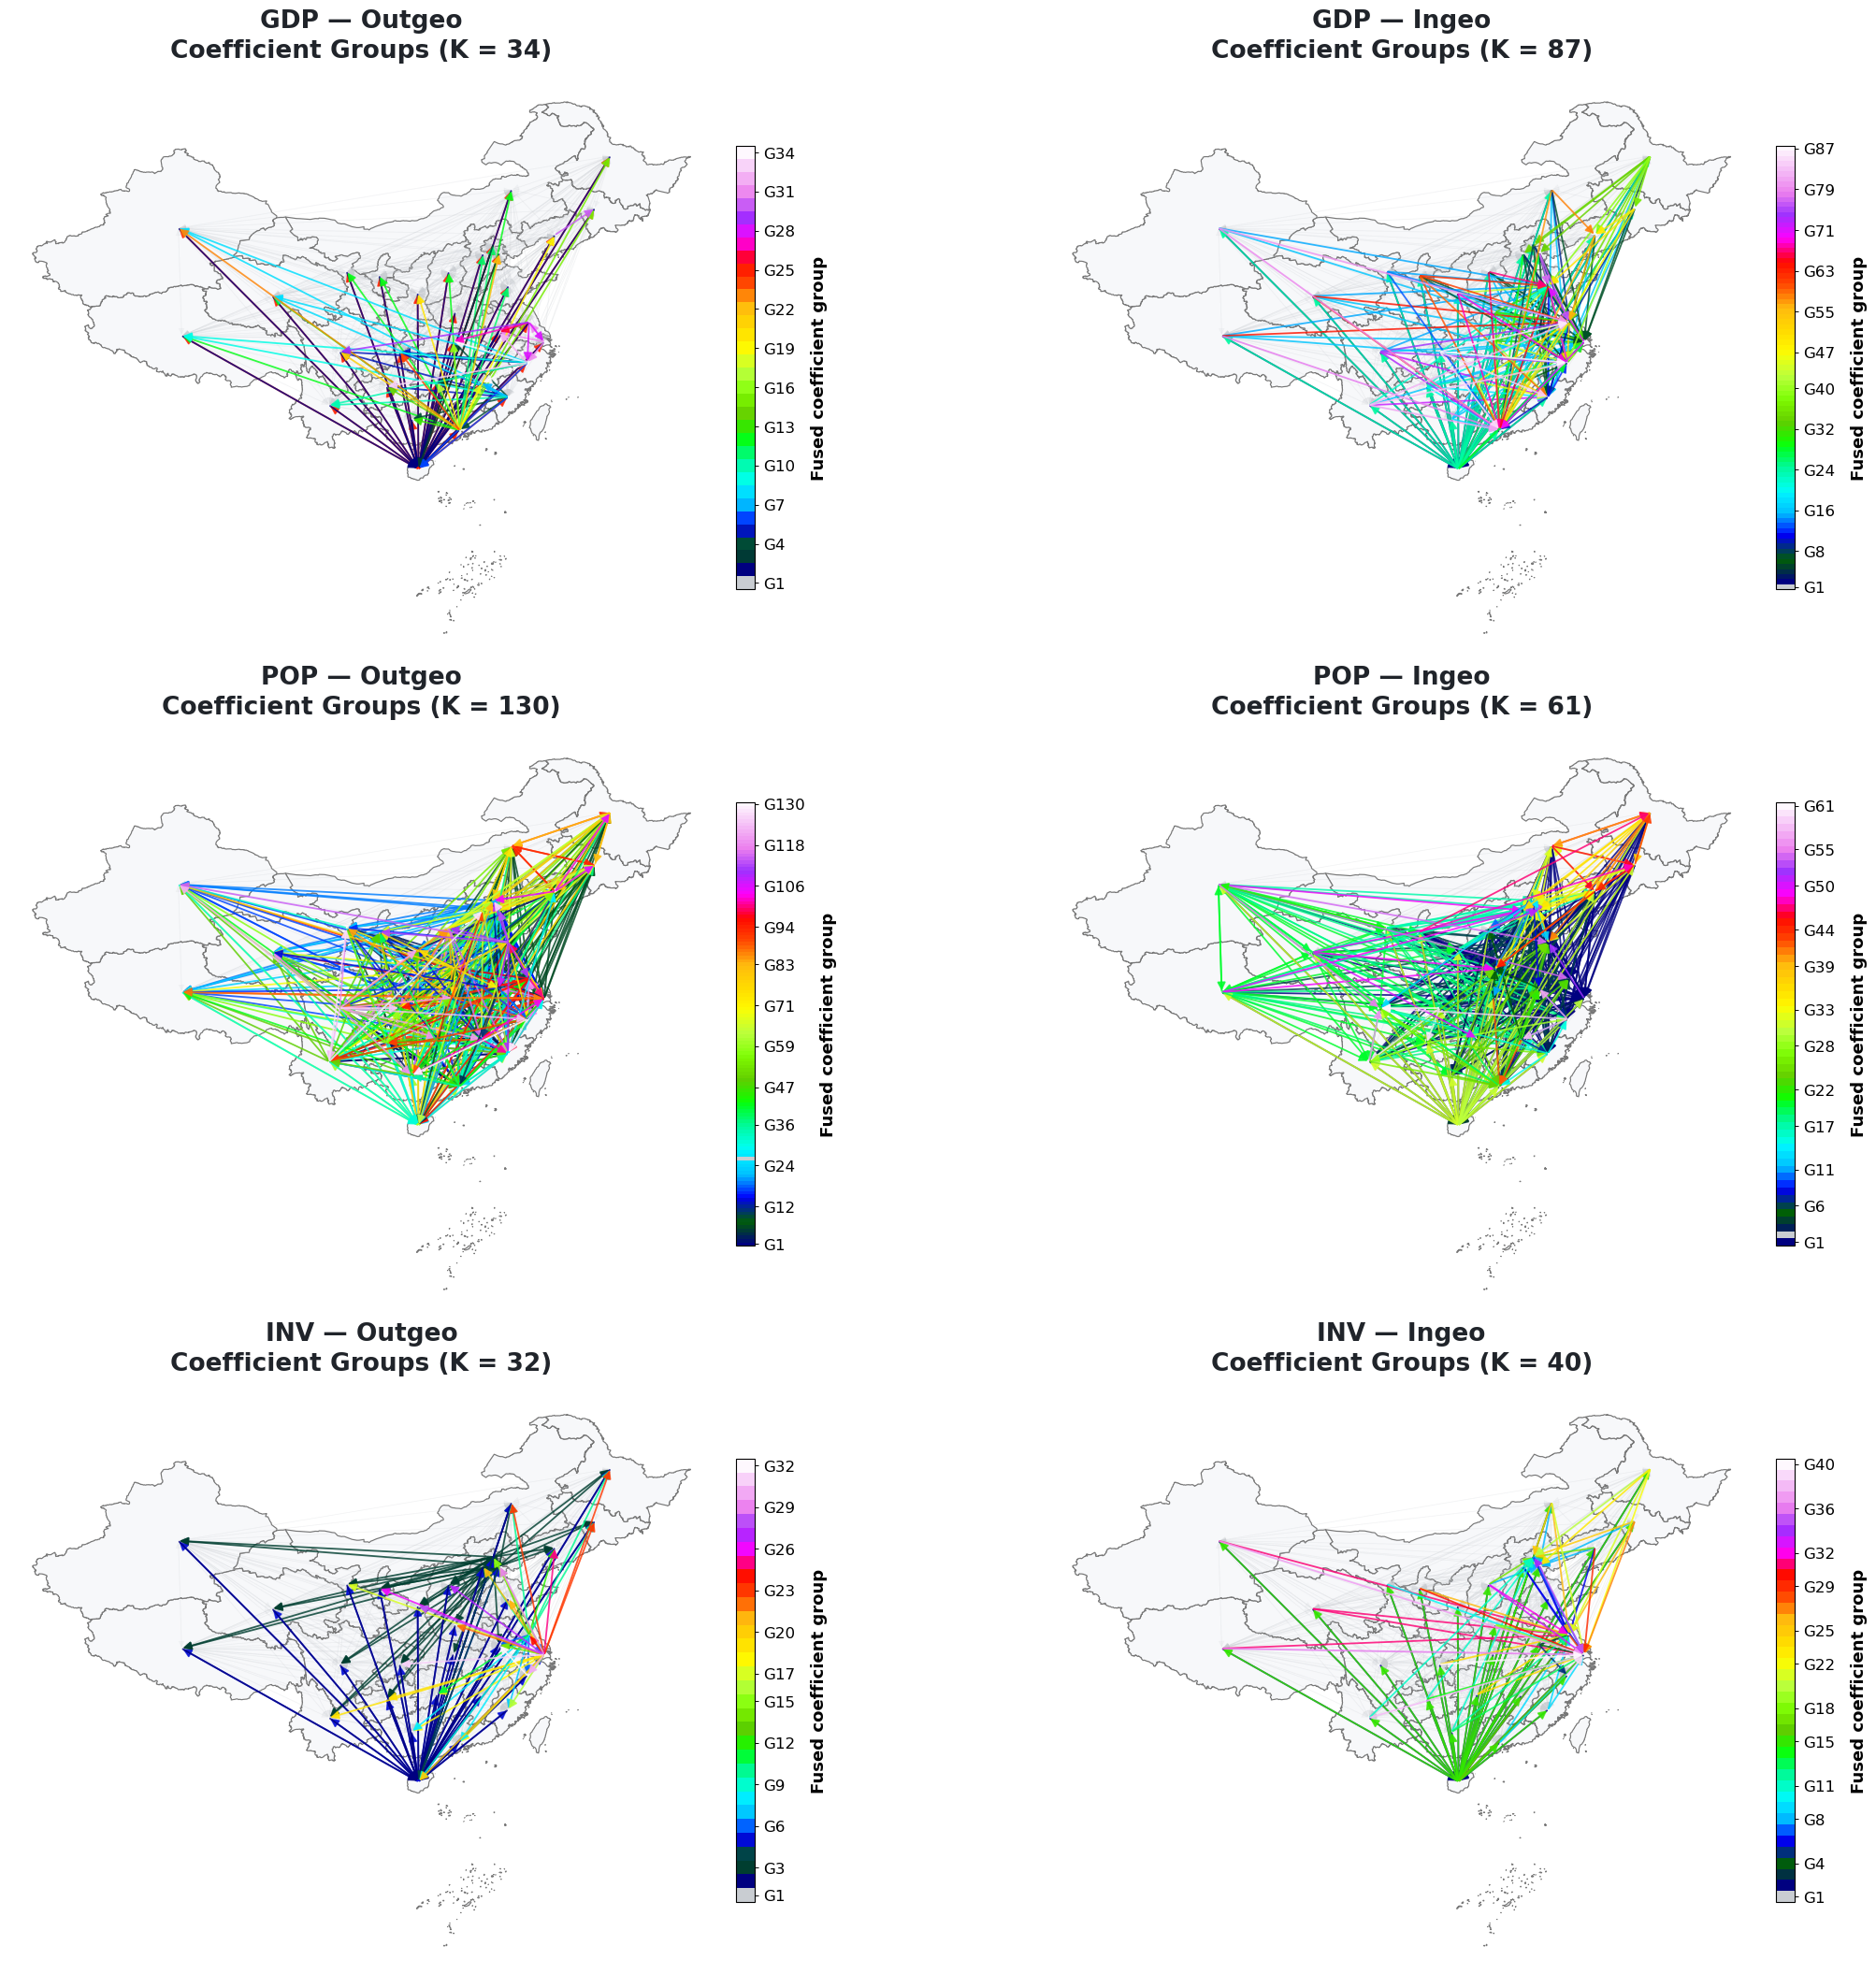

In [5]:
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 13,
    "axes.titlesize": 19,
    "axes.titleweight": "bold",
    "figure.titlesize": 25,
    "savefig.dpi": 400})

fig, axes = plt.subplots(len(feature_groups), 2, figsize=(22, 7 * len(feature_groups)), squeeze=False, constrained_layout=True)
base_palette = list(plt.get_cmap("tab20").colors)

for row_idx, (group_name, feat_out, feat_in) in enumerate(feature_groups):
    for col_idx, (feat, direction) in enumerate([(feat_out, "Outgeo"), (feat_in, "Ingeo")]):
        ax = axes[row_idx, col_idx]
        labels_all = np.asarray(group_cols[f"{feat}_group"], dtype=int).ravel()

        if len(labels_all) != len(df):
            raise ValueError(f"{feat}: fusion labels do not match the original flow-row order.")

        labels_valid = labels_all[valid_idx]
        if labels_valid.size == 0:
            ax.set_title(f"{group_name} — {direction}: No valid flows", fontsize=19, fontweight="bold")
            ax.axis("off")
            continue

        if np.any(labels_valid < 0):
            raise ValueError(f"Invalid ADMM fusion-group label for {feat}.")

        group_ids, group_counts = np.unique(labels_valid, return_counts=True)
        K = len(group_ids)
        dominant_group = int(group_ids[np.argmax(group_counts)])
        other_groups = [int(g) for g in group_ids if int(g) != dominant_group]

        if len(other_groups) <= len(base_palette):
            extra_palette = base_palette[:len(other_groups)]
        else:
            extra_palette = list(plt.get_cmap("gist_ncar", len(other_groups))(np.arange(len(other_groups))))

        group_color = {dominant_group: "#C9CDD2"}
        group_color.update({gid: extra_palette[i] for i, gid in enumerate(other_groups)})

        base_map.plot(ax=ax, color="#F7F8FA", edgecolor="#777777", linewidth=0.85, zorder=1)

        count_map = {int(g): int(c) for g, c in zip(group_ids, group_counts)}
        draw_order = sorted(range(len(valid_idx)), key=lambda pos: count_map[int(labels_valid[pos])], reverse=True)

        for pos in draw_order:
            obs_idx = int(valid_idx[pos])
            gid = int(labels_valid[pos])
            origin = pair_origin.iloc[obs_idx]
            dest = pair_dest.iloc[obs_idx]

            if origin is None or dest is None or origin.equals(dest):
                continue

            is_dominant = gid == dominant_group
            ax.annotate(
                "", xy=(dest.x, dest.y), xytext=(origin.x, origin.y),
                arrowprops=dict(arrowstyle="-|>", mutation_scale=10 if is_dominant else 13,
                                color=group_color[gid], lw=0.5 if is_dominant else 1.3,
                                alpha=0.13 if is_dominant else 0.82, shrinkA=1, shrinkB=1),
                zorder=2 if is_dominant else 4
            )

        sorted_group_ids = [int(g) for g in group_ids]
        cmap = ListedColormap([group_color[g] for g in sorted_group_ids])
        norm = BoundaryNorm(np.arange(K + 1) - 0.5, K)
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_array([])

        tick_pos = np.arange(K) if K <= 12 else np.unique(np.linspace(0, K - 1, 12, dtype=int))
        cbar = fig.colorbar(sm, ax=ax, fraction=0.04, pad=0.025, ticks=tick_pos, shrink=0.78, aspect=24)
        cbar.set_ticklabels([f"G{sorted_group_ids[i] + 1}" for i in tick_pos])
        cbar.ax.tick_params(labelsize=12, length=3, width=0.7)
        cbar.set_label("Fused coefficient group", fontsize=13, fontweight="bold", labelpad=12)

        ax.set_title(f"{group_name} — {direction}\nCoefficient Groups (K = {K})",
                     fontsize=19, fontweight="bold", color="#20242A", pad=20, linespacing=1.3)

        minx, miny, maxx, maxy = base_map.total_bounds
        dx, dy = maxx - minx, maxy - miny
        ax.set_xlim(minx - 0.035 * dx, maxx + 0.035 * dx)
        ax.set_ylim(miny - 0.035 * dy, maxy + 0.035 * dy)
        ax.set_aspect("equal", adjustable="box")
        ax.axis("off")

#fig.suptitle("FSCC Spatial Fusion Patterns", fontsize=25, fontweight="bold", color="#17212B")
plt.savefig("coef_arrows_grid.png", dpi=400, bbox_inches="tight", pad_inches=0.3, facecolor="white")
plt.savefig("coef_arrows_grid.pdf", bbox_inches="tight", pad_inches=0.3, facecolor="white")
plt.show()